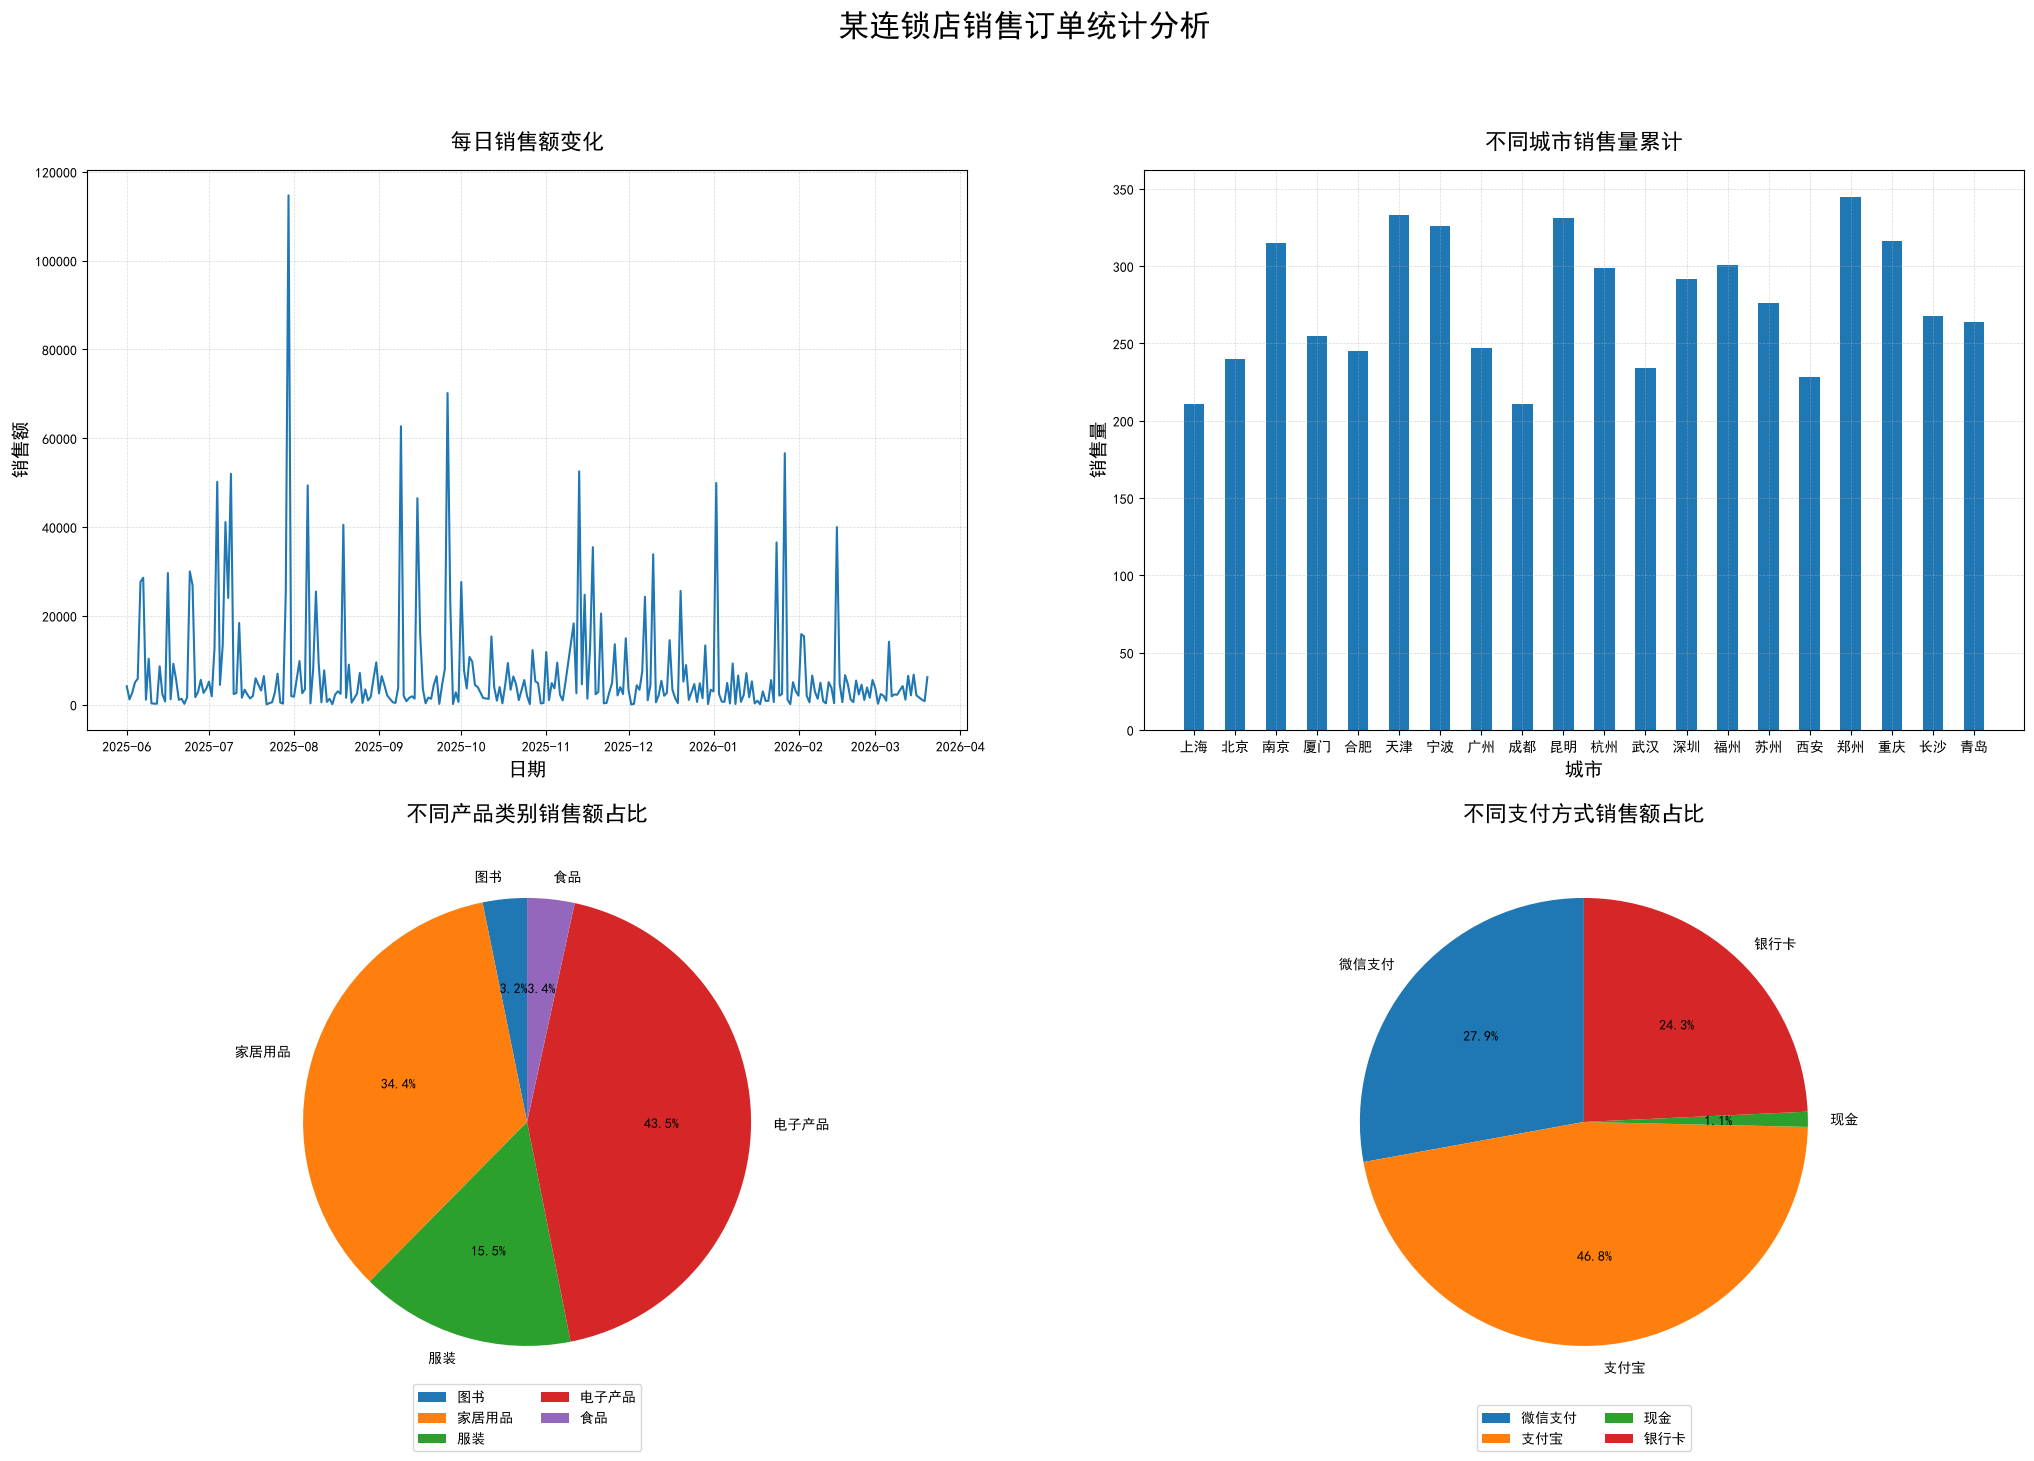

In [53]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['font.sans-serif'] = ['SimHei']

df = pd.read_csv("./resources/sales.csv", encoding="utf-8")

df['销售额'] = df['销售数量'] * df['单价']

# 对数据进行 清洗
# 删除缺失值：所在的一整行数据
df.dropna(inplace=True)

# 删除重复值
df.drop_duplicates(subset=["订单号"], inplace=True)

# 格式化时间
df["订单日期"] = df["订单日期"].str.replace("/", "-")
# 防止时间都挤在一起
df["订单日期"] = pd.to_datetime(df['订单日期'])

# 让单价都为正数
df["单价"] = df["单价"].abs()

# 开始绘制子图

figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(25, 16))

ax1 = axes[0, 0]
ax2 = axes[0, 1]
ax3 = axes[1, 0]
ax4 = axes[1, 1]

figure.suptitle("某连锁店销售订单统计分析", fontsize=22)

# 获取第一个子图的数据
changes_in_daily_sales = df.groupby("订单日期")["销售额"].sum()

# 获取  x轴和y轴的数据
ax1_x = changes_in_daily_sales.index
ax1_y = changes_in_daily_sales.values

# 绘制折线图
ax1.plot(ax1_x, ax1_y)
# 设置标题
ax1.set_title("每日销售额变化", fontsize=16, pad=15)

# 设置网格
ax1.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

# 设置x轴和y轴的标签    
ax1.set_xlabel("日期", fontsize=14)

ax1.set_ylabel("销售额", fontsize=14)

# 获取第二个子图的数据
cumulative_sales_volume_across_different_cities = df.groupby("客户所在城市")["销售数量"].sum()
# print(cumulative_sales_volume_across_different_cities)

# 获取  x轴和y轴的数据
ax2_x = cumulative_sales_volume_across_different_cities.index
ax2_y = cumulative_sales_volume_across_different_cities.values

# 绘制柱状图
ax2.bar(ax2_x, ax2_y, width=0.5)

# 设置标题
ax2.set_title("不同城市销售量累计", fontsize=16, pad=15)

# 设置网格
ax2.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

# 设置x轴和y轴的标签    
ax2.set_xlabel("城市", fontsize=14)

ax2.set_ylabel("销售量", fontsize=14)

# 获取第三个子图的数据
order_proportion_corresponding_to_different_product_types = df.groupby("产品类别")["销售额"].sum()
# print(order_proportion_corresponding_to_different_product_types)

# 获取  x轴和y轴的数据
ax3_x = order_proportion_corresponding_to_different_product_types.index
ax3_y = order_proportion_corresponding_to_different_product_types.values

# 绘制折线图
ax3.pie(ax3_y, labels=ax3_x, autopct='%1.1f%%', startangle=90)
# 设置标题
ax3.set_title("不同产品类别销售额占比", fontsize=16, pad=15)

ax3.legend(loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=2)

# 获取第四个子图的数据
order_proportion_corresponding_to_different_payment_methods = df.groupby("支付方式")["销售额"].sum()
# print(order_proportion_corresponding_to_different_payment_methods)

# 获取  x轴和y轴的数据
ax4_x = order_proportion_corresponding_to_different_payment_methods.index
ax4_y = order_proportion_corresponding_to_different_payment_methods.values

# 绘制折线图
ax4.pie(ax4_y, labels=ax4_x, autopct='%1.1f%%', startangle=90)
# 设置标题
ax4.set_title("不同支付方式销售额占比", fontsize=16, pad=15)

ax4.legend(loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=2)

plt.show()
